## Authors: Jonathan Yik Chang Ting

**email:** Jonathan.Ting@anu.edu.au

# Introduction

**archetypes.py** is a python package developed by Benyamin Motevalli in DATA61 (CSIRO) that implements the "Archetpye Analysis" by Adele Cutler and Leo Breiman, Technometrics, November 1994, Vol.36, No.4, pp. 338-347. The aim is to make the package consistent with sklearn library for the machine learning community. Accordingly, the package has three main functions: **fit, fit_transform, and transform**. In addition, a number of utility functions are included in the package that provides a range of visualisation functionalities. This tutorial demonstrates how to use this package.

# Required Packages

- numpy
- scipy.optimize
- matplotlib
- pandas

# Archetypal Analysis for Skeleton Data Set

The skeleton data set is an interesting real world case, which was also used in: **From Spider-Man to Hero -- Archetypal Analysis in R**. The set includes 507 data from which 247 are men and 260 are women. The data was collected by Heinz et al. (Heinz G, Peterson LJ, Johnson RW, Kerk CJ (2003). “Exploring Relationships in Body Dimensions.” Journal of Statistics Education, 11(2). URL http://www.amstat.org/publications/jse/v11n2/datasets.heinz.html). The features are the body girth measurements, skeleton diameter, age, weight, height, and gender. Here we show how to use our archetype analysis package to extract the archetypes as demonstrated in the R package, as well visualising the archetype profiles, finding the most archetypal data points, mapping and visualising data points in the archetype space, and the use of radar plots to visualise the contributions of the archetypes in describing any other data point.

**Let's get started!**

In [1]:
%load_ext autoreload
%autoreload 2

from archetypes import *
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# Get the Data

The skeleton data set is downloaded from the following link: 'http://jse.amstat.org/datasets/body.dat.txt'

In [2]:
import requests
url = 'http://jse.amstat.org/datasets/body.dat.txt'
r = requests.get(url)
data = np.array(list(map(lambda x: list(map(float, x.split())), r.text.splitlines())))
print(data.shape)

(507, 25)


In [128]:
# Bimetallic nanoparticles data
import pickle 

eleComb = 'PdPt'
# with open(f"data/dfCleaneds/dfCleaned_{eleComb}.pickle", 'rb') as f: 
#     df = pickle.load(f)
with open(f"data/dfScaledNoLVHCs/dfScaledNoLVHC_{eleComb}_V1C99.pickle", 'rb') as f: 
    dfNormalised = pickle.load(f)
dfNormalised

,T,P,N_atom_total,N_Pd,N_Pt,N_atom_bulk,N_atom_surface,Vol_bulk_pack,Vol_sphere,R_min,...,q6q6_S_18,q6q6_S_19,q6q6_S_20,q6q6_S_20+,FCC,HCP,ICOS,DECA,Total_E,Formation_E
0,336.74795,17.117479,1163,552,611,637,526,17340.83252,7297.042284,12.554528,...,0,0,0,0,613,2,0,0,-5115.4493,568.3407
1,354.89404,18.045223,1163,552,611,638,525,17340.83252,7295.743272,12.548826,...,0,0,0,0,614,2,0,0,-5112.7421,571.0479
2,415.27025,21.102366,1163,552,611,638,525,17340.83252,7296.838036,12.549544,...,0,0,0,0,610,2,0,0,-5103.5929,580.1971
3,439.91337,22.362704,1163,552,611,639,524,17340.83252,7293.684691,12.549285,...,0,0,0,0,615,2,0,0,-5100.7419,583.0481
4,466.53941,23.726458,1163,552,611,640,523,17340.83252,7297.518377,12.538412,...,0,0,0,0,615,3,0,0,-5098.5846,585.2054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151211,2419.64140,123.509530,695,30,665,366,329,10483.97910,4343.844255,9.327007,...,0,0,0,0,12,18,12,13,-3353.7898,600.5602
151212,2541.02220,129.692460,695,30,665,365,330,10483.97910,4370.234132,9.854140,...,0,0,0,0,3,8,13,6,-3342.8391,611.5109
151213,2496.91310,127.448770,695,30,665,368,327,10483.97910,4371.210578,9.880524,...,0,0,0,0,7,8,18,4,-3345.7172,608.6328
151214,2699.42690,137.776930,695,30,665,366,329,10483.97910,4357.498184,9.755413,...,0,0,0,0,11,22,10,4,-3328.9998,625.3502


## Using similar columns of data to "From Spider-Man to Hero -- Archetypal Analysis in R"

As seen, skeleton data set has 25 features, however, only 11 were used in **From Spider-Man to Hero -- Archetypal Analysis in R**. Here, we will use similar dataset so that users could compare the results. We also try to order the columns in the similar order that appears in R package.

In [3]:
columns = ['AnkleDiam', 'KneeDiam', 'WristDiam', 'Bitro', 'Biil',
        'ElbowDiam', 'ChestDiam', 'ChestDp', 'Biac', 'Height', 'Gender']

gender = {1.0: 'male', 0.0: 'female'}

selected_cols = [8, 7, 6, 2, 1, 5, 4, 3, 0, 23, 24]
df = pd.DataFrame(data[:, selected_cols], columns = columns)
df['Gender'] = df.apply(lambda row: gender[row['Gender']], axis = 1)

In [4]:
df.sample(10)

,AnkleDiam,KneeDiam,WristDiam,Bitro,Biil,ElbowDiam,ChestDiam,ChestDp,Biac,Height,Gender
360,13.1,18.1,10.9,29.3,25.9,13.2,29.1,14.7,35.7,169.4,female
261,12.2,16.8,8.6,31.6,26.5,11.5,23.7,18.3,35.0,160.0,female
134,15.1,19.0,10.7,29.9,25.6,14.1,25.2,23.3,41.1,190.5,male
482,13.4,17.9,9.8,32.6,31.5,12.9,25.2,17.5,35.8,175.3,female
55,13.0,18.8,10.4,30.2,25.2,13.2,26.4,17.0,38.3,163.0,male
147,14.3,18.0,10.4,31.5,26.8,12.9,27.8,18.0,38.7,180.3,male
38,15.4,19.0,10.8,30.4,27.5,13.6,28.0,18.7,36.2,177.8,male
113,15.4,19.4,11.8,34.2,31.7,13.8,34.0,22.8,41.1,174.0,male
86,13.6,20.2,12.3,30.5,26.3,14.4,30.6,19.7,43.2,177.0,male
442,13.8,18.8,10.2,33.1,29.0,12.2,25.9,16.3,38.9,168.9,female


In [109]:
lst_feat = ['AnkleDiam', 'KneeDiam', 'WristDiam', 'Bitro', 'Biil',
        'ElbowDiam', 'ChestDiam', 'ChestDp', 'Biac', 'Height']

## Scaling the data

In [110]:
sc = StandardScaler()
X = df[lst_feat].values
X_scaled = sc.fit_transform(X)

In [131]:
# Bimetallic nanoparticle data
sc = StandardScaler()
X = dfNormalised.iloc[:, :-2].values
X_scaled = sc.fit_transform(X)
X_scaled

array([[-1.92170867, -1.16307145, -0.12647628, ...,  6.33213245,
        -0.69787885, -0.68256018],
       [-1.89300165, -1.15375634, -0.12647628, ...,  6.28293006,
        -0.69787885, -0.68256018],
       [-1.79748681, -1.12306078, -0.12647628, ...,  6.13532289,
        -0.69787885, -0.68256018],
       ...,
       [ 1.49566115, -0.05527881, -0.5170385 , ..., -0.40859498,
         0.02735153, -0.47376788],
       [ 1.81603691,  0.04842214, -0.5170385 , ..., -0.40859498,
        -0.29497308, -0.47376788],
       [ 1.73906891,  0.02378923, -0.5170385 , ..., -0.40859498,
        -0.05322962,  0.04821287]])

## Creating an archetype instance

### Description of arguments

**n_archetypes**: defines how many archetypes will be extracted. A positive integer. Note n_archetypes = 1 would return the mean of the data set (see "Archetype Analysis" by Adele Cutler and Leo Breiman, Technometrics, November 1994, Vol.36, No.4, pp. 338-347.) <br><br>
**tolerance**: defines when to stop optimisation. It checks convergence of residual sum of squares (RSS) <br>
**max_iter**:       maximum number of iterations for optmisation. <br><br>
**random_state**:   random seed number. <br><br>
**C**:              the weight on the constraint equation. Smaller is the weight, stronger is the constraint. Constraint Eq.: $$\sum\alpha = 1,$$ $$\sum\beta = 1$$

**initialize**: three different initialization techniques are implemented:
- 'random': randomly selects a set of archetypes from the feature space. 
- 'random_idx': randomly selects a set of data points as initial archetypes.
- 'furthest_sum': Uses the furthest sum to efficiently initialize the archetypes. The idea is taken from a recent paper: Archetypal analysis for machine learning and data mining, Morten Morup and Lars Kai Hansen. 

**redundancy_try**: Depending on the initialisation, the set of archetypes may be redundant. Once redundancy occurs, alfa values corresponding to the redundant archetype becomes zero. In such circumstance, the algorithm searches for new candidate point to resolve redundancy. redundancy_try controls the number of tries by the algorithm to resolve redundancy. If not resolved, algorithm reduces the number of archetypes. For details on this issue, refer to "Archetype Analysis" by Adele Cutler and Leo Breiman, Technometrics, November 1994, Vol.36, No.4, pp. 338-347.

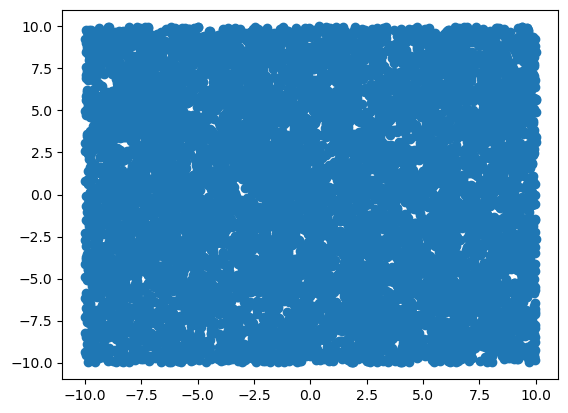

In [2]:
# from sklearn.datasets import load_diabetes
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import KFold
from sklearn.metrics import explained_variance_score
from spams import archetypalAnalysis

NUM_SAMPLES, NUM_ARCHETYPES, RANDOM_STATE = 10000, 3, 42

# Generate data
x = np.random.uniform(-10, 10, NUM_SAMPLES)
y = np.random.uniform(-10, 10, NUM_SAMPLES)
z = np.random.uniform(-10, 10, NUM_SAMPLES)
X = np.array([[xi, yi] for xi, yi in zip(x, y)])
# X = np.array([[xi, yi, zi] for xi, yi, zi in zip(x, y, z)])
# X, y_true = make_blobs(n_samples=NUM_SAMPLES, centers=1, cluster_std=30, random_state=0)
# diabetes = load_diabetes()
# X, y = diabetes.data, diabetes.target
# diabetes.feature_names

# Visualise data
# for k, col in enumerate(['k']):
#     cluster_data = y_true == k
#     plt.scatter(X[cluster_data, 0], X[cluster_data, 1], c=col)
plt.scatter(X[:, 0], X[:, 1])

# Standardise data
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [159]:
%%time
NUM_FOLD = 3
kf = KFold(n_splits=NUM_FOLD, shuffle=True, random_state=RANDOM_STATE)  # Split data
allArchetypes, allAlphas, testIndices = [], [], []
for i, (train_index, test_index) in enumerate(kf.split(X_scaled)):
    X_fold = X_scaled[test_index, :]
    Z, A, B = archetypalAnalysis(np.asfortranarray(X_fold.T), p=4, returnAB=True, robust=False, epsilon=0.001, randominit=False)
    allArchetypes.append(Z)
    allAlphas.append(A.toarray())
    testIndices.append(test_index)
    X_appr = np.matmul(Z, A.toarray())
    expVar = explained_variance_score(X_fold, X_appr.T)
    print(f"  Fold {i} Explained subset variance: {expVar}")
    print(f"  Fold {i} archetypes: {Z}")

# Without running another time of archetypal analysis
X_apprs = []
for i in range(len(allArchetypes)):
    X_fold_appr = np.matmul(allArchetypes[i], allAlphas[i])
    X_apprs.append(X_fold_appr)
X_final_appr = np.concatenate(X_apprs, axis=1)
print(f"Overall archetype explained variance: {explained_variance_score(X_scaled, X_final_appr.T)}")

# Extract final set of archetypes from the collected archetypes
archetypes = np.concatenate(allArchetypes, axis=1)
Z_combinedSet, A, B = archetypalAnalysis(np.asfortranarray(archetypes), p=4, returnAB=True, robust=False, epsilon=0.001, randominit=False)
print(f"Final archetype set: {Z_combinedSet}")

RSS FISTA = 1205.2625
RSS FISTA = 607.31151
RSS FISTA = 507.87813
RSS AS = 392.31628
RSS AS = 312.76531
RSS AS = 233.41788
RSS AS = 162.21514
RSS AS = 108.13264
RSS AS = 71.716657
RSS AS = 48.180542
RSS AS = 33.542921
RSS AS = 24.001073
RSS AS = 17.517783
RSS AS = 13.095906
RSS AS = 9.9912592
RSS AS = 7.7778251
RSS AS = 6.1694954
RSS AS = 4.9895627
RSS AS = 4.050419
RSS AS = 3.3364766
RSS AS = 2.7822498
RSS AS = 2.346138
RSS AS = 1.997964
RSS AS = 1.7308418
RSS AS = 1.5101005
RSS AS = 1.3241683
RSS AS = 1.1663723
RSS AS = 1.0320512
RSS AS = 0.91745884
RSS AS = 0.81920659
RSS AS = 0.7345562
RSS AS = 0.66128007
RSS AS = 0.59770273
RSS AS = 0.54240674
RSS AS = 0.49398693
RSS AS = 0.45528735
RSS AS = 0.42808939
RSS AS = 0.4035882
RSS AS = 0.38314037
RSS AS = 0.365959
RSS AS = 0.35029213
RSS AS = 0.335976
RSS AS = 0.32285625
RSS AS = 0.31081059
RSS AS = 0.29971713
RSS AS = 0.28936892
RSS AS = 0.27976965
RSS AS = 0.27085714
RSS AS = 0.26255558
RSS AS = 0.25480356
RSS AS = 0.24755306
RSS AS =

In [117]:
%%time
Z_wholeSet, A, B = archetypalAnalysis(np.asfortranarray(X_scaled.T), p=4, returnAB=True, robust=False, epsilon=0.001, randominit=False)
X_appr = np.matmul(Z_wholeSet, A.toarray())
expVar = explained_variance_score(X_scaled, X_appr.T)
print(f"\nExplained variance: {expVar}")
print(f"Archetype set: {Z_wholeSet}")

RSS FISTA = 3223.6479
RSS FISTA = 845.60074
RSS FISTA = 387.38369
RSS AS = 202.22408
RSS AS = 110.08703
RSS AS = 68.874621
RSS AS = 46.746577
RSS AS = 33.697395
RSS AS = 25.111691
RSS AS = 19.224576
RSS AS = 15.17939
RSS AS = 12.232707
RSS AS = 9.9802601
RSS AS = 8.2352842
RSS AS = 6.8643259
RSS AS = 5.7735257
RSS AS = 4.8942073
RSS AS = 4.1779154
RSS AS = 3.5937352
RSS AS = 3.1137151
RSS AS = 2.7102021
RSS AS = 2.372012
RSS AS = 2.0867148
RSS AS = 1.8444162
RSS AS = 1.6374173
RSS AS = 1.4605673
RSS AS = 1.3067404
RSS AS = 1.1741645
RSS AS = 1.0582283
RSS AS = 0.95645589
RSS AS = 0.86692506
RSS AS = 0.78801361
RSS AS = 0.71836804
RSS AS = 0.65677232
RSS AS = 0.60208627
RSS AS = 0.55425648
RSS AS = 0.51256114
RSS AS = 0.47507346
RSS AS = 0.44493619
RSS AS = 0.41186226
RSS AS = 0.38387937
RSS AS = 0.35866756
RSS AS = 0.3357636
RSS AS = 0.3149045
RSS AS = 0.30010119
RSS AS = 0.2798032
RSS AS = 0.26355599
RSS AS = 0.24850539
RSS AS = 0.2346148
RSS AS = 0.22178621
RSS AS = 0.20992405
RSS AS

In [161]:
archetypes = np.concatenate(allArchetypes, axis=1)
Z_combinedSet, A, B = archetypalAnalysis(np.asfortranarray(archetypes), p=4, returnAB=True, robust=False, epsilon=0.001, randominit=False)
archetypes_appr = np.matmul(Z_combinedSet, A.toarray())
expVar = explained_variance_score(archetypes, archetypes_appr)
print(f"\nExplained variance: {expVar}")
print(f"Final archetype set: {Z_combinedSet}")

Explained variance: 0.9728847671624061RSS FISTA = 0.010730549
RSS FISTA = 0.0093049222
RSS FISTA = 0.0092940853
RSS AS = 0.0079880993
RSS AS = 0.0076282006
RSS AS = 0.0075356452
RSS AS = 0.0074955751
RSS AS = 0.0074782367
RSS AS = 0.0074707345
RSS AS = 0.0074674876
RSS AS = 0.0074660816
RSS AS = 0.0074654724
RSS AS = 0.0074652083
RSS AS = 0.0074650938
RSS AS = 0.0074650441
RSS AS = 0.0074650225
RSS AS = 0.0074650131
RSS AS = 0.007465009
RSS AS = 0.0074650072
RSS AS = 0.0074650064
RSS AS = 0.0074650061
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0.007465006
RSS AS = 0

Archetype set from split subsets:
[[ 1.64162424  1.71114979 -1.70405738 -1.71593371]
 [ 1.69408602 -1.66329658 -1.63901343  1.69523182]]
Archetype set from whole dataset:
[[ 1.64346454 -1.6923056  -1.71597393  1.71119814]
 [ 1.71057433 -1.70477595  1.68240608 -1.66701905]]


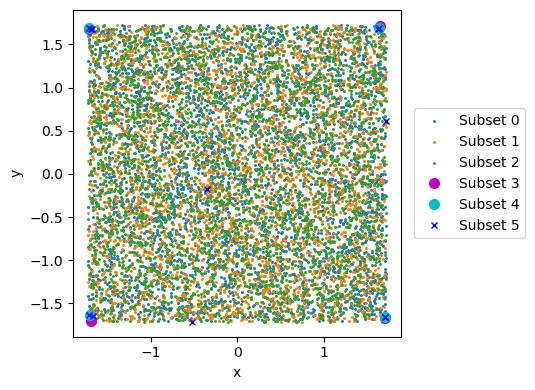

In [172]:
print(f"Archetype set from split subsets:\n{Z_combinedSet}")
print(f"Archetype set from whole dataset:\n{Z_wholeSet}")

# Plot the data and archetypes from both approaches
plt.figure(figsize=(6, 4))
# plt.scatter(X_scaled[:, 0], X_scaled[:, 1], marker='.', color='y')
for testIndex in testIndices:
    plt.scatter(X_scaled[testIndex, 0], X_scaled[testIndex, 1], marker='.', s=5)
plt.plot(Z_wholeSet[0, :], Z_wholeSet[1, :], 'o', markersize=7, color='m')
plt.plot(Z_combinedSet[0, :], Z_combinedSet[1, :], 'o', markersize=7, color='c')
plt.plot(archetypes[0, :], archetypes[1, :], 'x', markersize=5, color='b')
plt.xlabel('x')
plt.ylabel('y')
NUM_FOLD = 10
legendEntries = [f"Subset {i}" for i in range(NUM_FOLD)] + ['Whole Set Archetypes', 'Combined Split Set Archetypes', 'Split Set Archetypes']
plt.legend(legendEntries, loc='center right', bbox_to_anchor=(1.4, 0.5), ncol=1, fancybox=True, shadow=False)
plt.tight_layout()

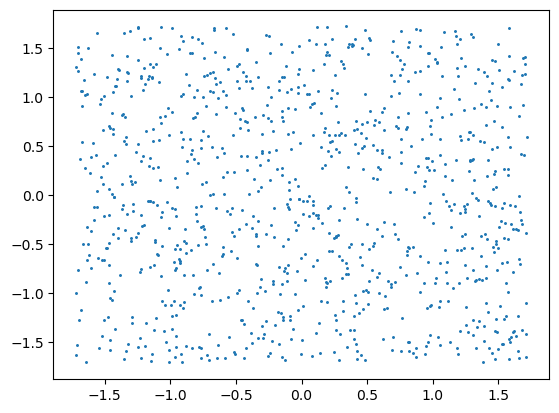

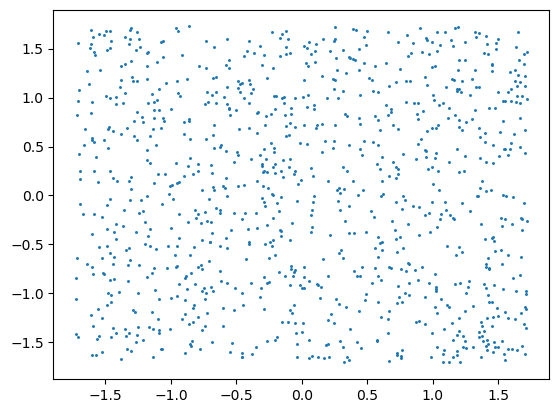

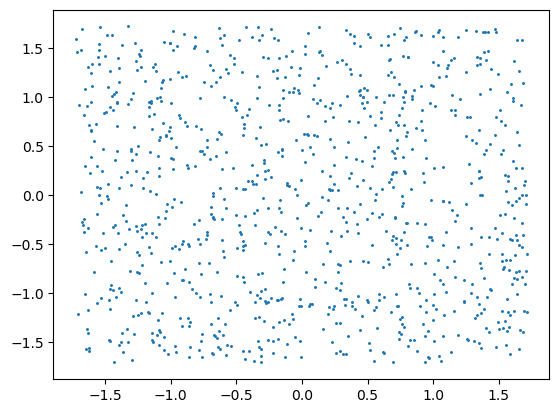

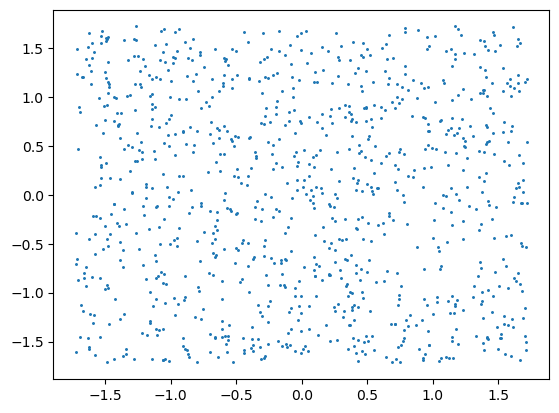

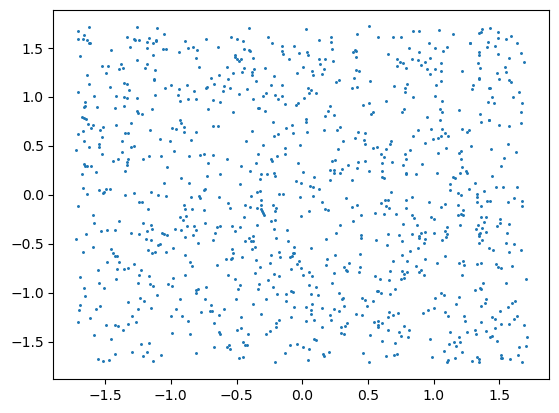

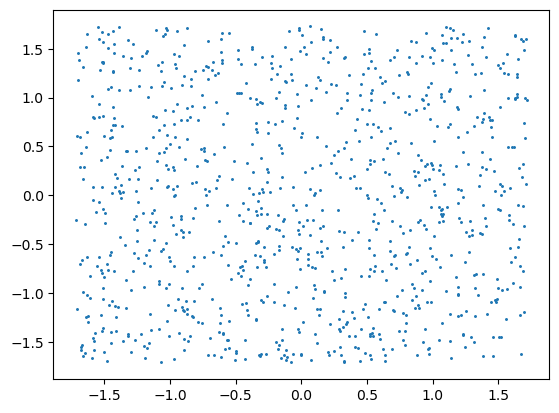

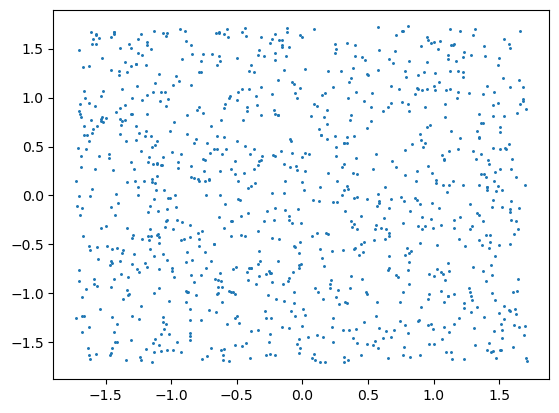

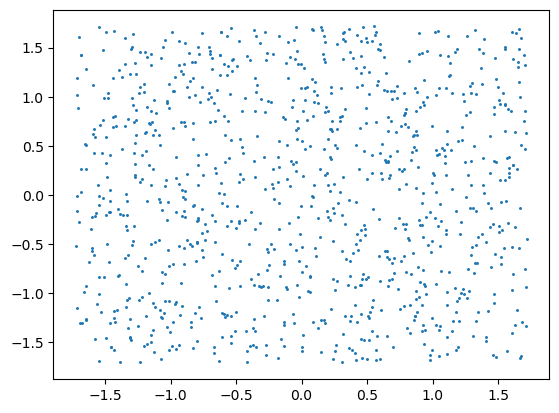

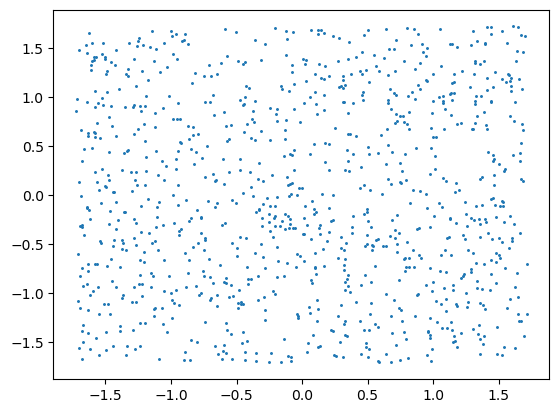

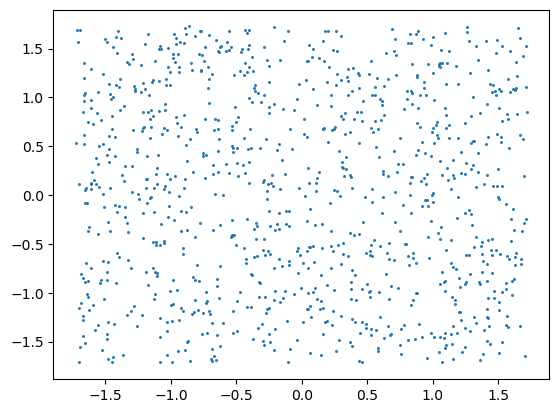

In [158]:
for testIndex in testIndices:
    plt.scatter(X_scaled[testIndex, 0], X_scaled[testIndex, 1], marker='.', s=5)
    plt.show()

In [199]:
%%time
kf = KFold(n_splits=2, shuffle=False, random_state=None)  # Split data
allArchetypes, allAlphas = [], []
for i, (train_index, test_index) in enumerate(kf.split(X_scaled)):
    X_fold = X_scaled[test_index, :]
    AA = ArchetypalAnalysis(n_archetypes=NUM_ARCHETYPES, tolerance=0.001, max_iter=200, random_state=RANDOM_STATE, C=0.0001, initialize='furthest_sum', redundancy_try=30)
    AA.fit(X_fold)
    # print(AA.archetypes.shape, AA.alfa.shape)
    allArchetypes.append(AA.archetypes)
    allAlphas.append(AA.alfa)
    print(f"  Fold {i} Explained subset variance: {AA.explained_variance_}")
    print(f"  Fold {i} archetypes: {AA.archetypes}")

X_apprs = []
for i in range(len(allArchetypes)):
    X_fold_appr = np.matmul(allArchetypes[0], allAlphas[0])
    X_apprs.append(X_fold_appr)
    
X_final_appr = np.concatenate(X_apprs, axis=1)
# archetypes = np.concatenate(allArchetypes, axis=1).T
# alphas = np.concatenate(allAlphas, axis=1)
# print(archetypes.shape, alphas.shape)

# AA = ArchetypalAnalysis(n_archetypes=NUM_ARCHETYPES, tolerance=0.001, max_iter=200, random_state=0, C=0.0001, initialize='random', redundancy_try=30)
# AA.fit(archetypes)
# X_appr = np.matmul(AA.archetypes, AA.alfa)
# print(f"Archetype set explained variance: {AA.explained_variance_}")
# X_final_appr = np.matmul(AA.archetypes, alphas)
print(f"Overall archetype explained variance: {explained_variance_score(X_scaled, X_final_appr.T)}")
# AA.archetypes

  Fold 0 Explained subset variance: 0.615562286265041
  Fold 0 archetypes: [[-1.71811449  1.57173569  0.81188916]
 [ 0.401875    1.59902864 -1.73270297]
 [ 0.14309834  1.60788647 -1.45660898]]
  Fold 1 Explained subset variance: 0.6203792894830538
  Fold 1 archetypes: [[-1.71786302  1.58696942  0.79304848]
 [ 0.4150442   1.59591116 -1.71785429]
 [ 0.13378452  1.59533607 -1.52352212]]
Overall archetype explained variance: 0.06921683324324623
CPU times: user 4.18 s, sys: 4.03 ms, total: 4.19 s
Wall time: 4.18 s


In [20]:
%%time
AA = ArchetypalAnalysis(n_archetypes=4, tolerance=0.001, max_iter=200, random_state=RANDOM_STATE, C=0.0001, initialize='furthest_sum', redundancy_try=30)
AA.fit(X_scaled)
print(f"Explained variance: {AA.explained_variance_}")
AA.archetypes

Explained variance: 0.9999945590633368
CPU times: user 1.43 s, sys: 18 µs, total: 1.43 s
Wall time: 1.43 s


array([[-1.71593371,  1.71116064,  1.65226837, -1.69805704],
       [ 1.69523182, -1.68580523,  1.70966279, -1.70519845]])

## Extract archetypes

In [279]:
AA.fit(X_scaled)

**.explained_variance_** returns the variance explained by the archetype set. It can be used as a measure to identify
number of archetypes (e.g. using elbow plot)

In [280]:
print(AA.explained_variance_)

0.9997983419200613


**.archetypes** returns the extracted archetypes. Note that the array shape is n_features x n_archetypes

In [281]:
AA.archetypes

array([[-0.62035556,  3.04017438, -1.42065549,  3.90170136, -3.61795707],
       [ 3.22589078, -1.84915092, -3.35391098,  2.34438711,  1.11870002]])

**.archetype_profile** provides the profile of the archetypes. It shows each archetype is high in which features and low in which. **.archetype_profile** has similar shape to **.archetypes**. Further, the numbers are between 0 to 1. You can multiply it by 100 to convert them to percentange. 

In [207]:
AA.archetype_profile

array([[0.86      , 0.99666667, 0.00333333, 0.27666667, 0.67666667],
       [0.01      , 0.50666667, 0.80666667, 0.01      , 0.99666667]])

**NOTE**: You can also have access to number of archetypes as well as optimised $\alpha$ and $\beta$ through **.n_archertypes**, **.alfa**, and **.beta**. 

# Selecting number of archetypes with elbow plot

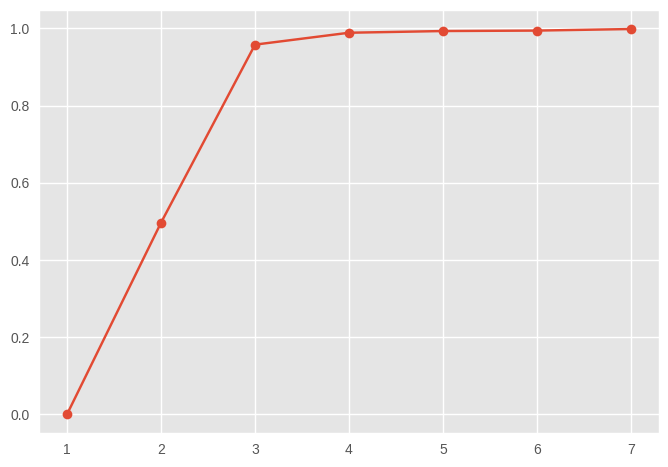

In [208]:
n_archs = list(range(1, 8))

lst_exp_var = []
for n_arch in n_archs:
    AA = ArchetypalAnalysis(n_archetypes = n_arch, 
                        tolerance = 0.001, 
                        max_iter = 200, 
                        random_state = 0, 
                        C = 0.0001, 
                        initialize = 'random',
                        redundancy_try = 30)
    AA.fit(X_scaled)
    lst_exp_var.append(AA.explained_variance_)

# plt.style.use('seaborn')
plt.plot(n_archs, lst_exp_var, '-o')
plt.show()

As seen, elbow occurs with three archetypes. Hence, we continue with three archetypes. Also, with three archetypes you can compare the results with the ones reported in **From Spider-Man to Hero -- Archetypal Analysis in R**.

In [222]:
AA = ArchetypalAnalysis(n_archetypes = 5, 
                        tolerance = 0.001, 
                        max_iter = 200, 
                        random_state = 0, 
                        C = 0.0001, 
                        initialize = 'random',
                        redundancy_try = 30)

AA.fit(X_scaled)

## Simplex plot: Mapping datapoints to archetype convex hull

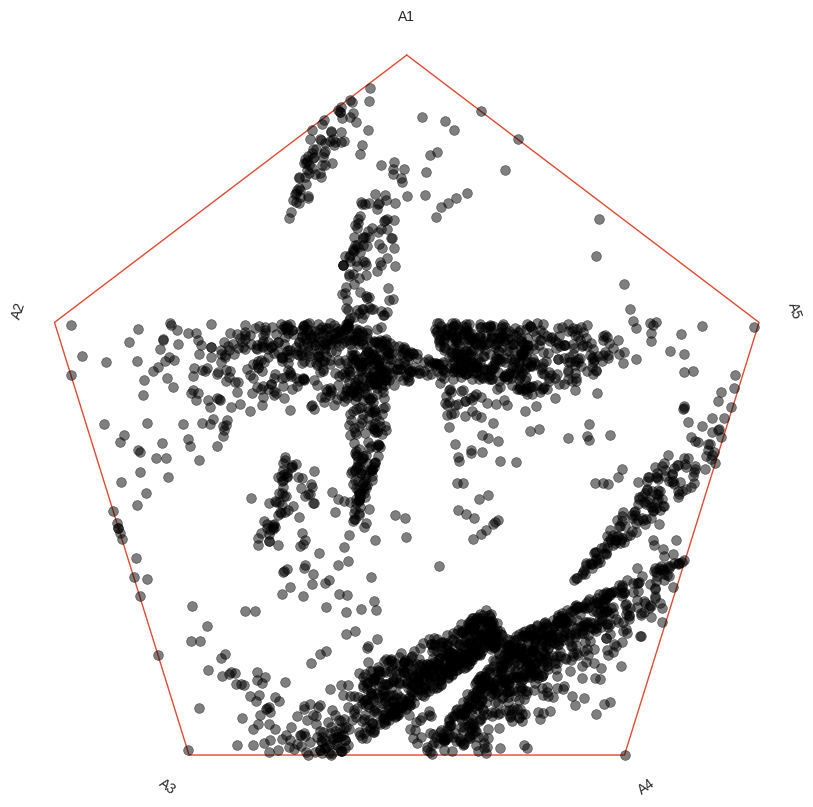

In [283]:
AA.plot_simplex(AA.alfa)

### Enriching Simplex Plot

For a rich visualisation you have the flexibility to assign attributes to the data point. Three main properties can be controlled: marker color, marker shape, and marker size.

#### Initializing the df_args

In [90]:
df_args = df[['Gender']]

In [98]:
df_args['color'] = 'red'
df_args.loc[:]['color'][df_args['Gender']=='female'] = 'blue'

df_args['marker'] = 'v'
df_args.loc[:]['marker'][df_args['Gender']=='female'] = 's'

df_args['size'] = df[['Height']]

plot_args = {'color': df_args['color'], 's': df_args['size'], 'marker': df_args['marker']}
df_args

/tmp/ipykernel_860267/3979262807.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_args['color'] = 'red'
/tmp/ipykernel_860267/3979262807.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_args['marker'] = 'v'
/tmp/ipykernel_860267/3979262807.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.ht

,Gender,color,marker,size
0,male,red,v,174.0
1,male,red,v,175.3
2,male,red,v,193.5
3,male,red,v,186.5
4,male,red,v,187.2
...,...,...,...,...
502,female,blue,s,176.5
503,female,blue,s,164.4
504,female,blue,s,160.7
505,female,blue,s,174.0


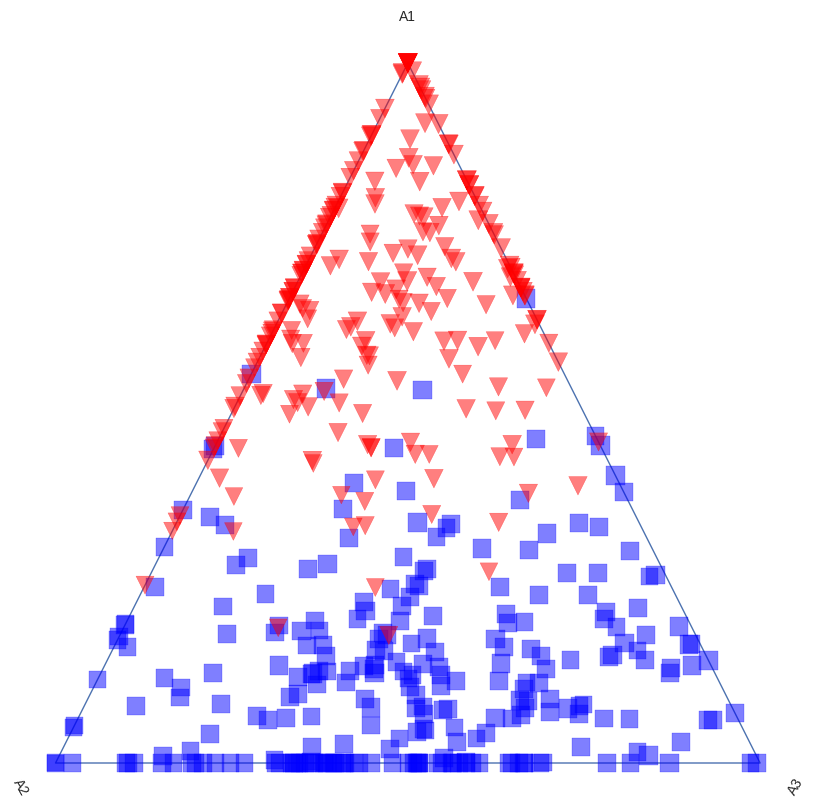

In [97]:
AA.plot_simplex(AA.alfa, plot_args)

# More flexibilty to visualise data in Simplex Plots

Additional utility functions are included in the package to give more flexibities to create simplex plots and color the data points in different fashions. To do this, three steps should be taken. First, you need to create the simplex plot frame with **create_simplex_ax** utility function, then you need to map the **alfa** values to the simplex frame using the **map_alfa_to_simplex** utility function, at last you can use standard matplotlib scatter plot to visualise data points. Let's see how it works.

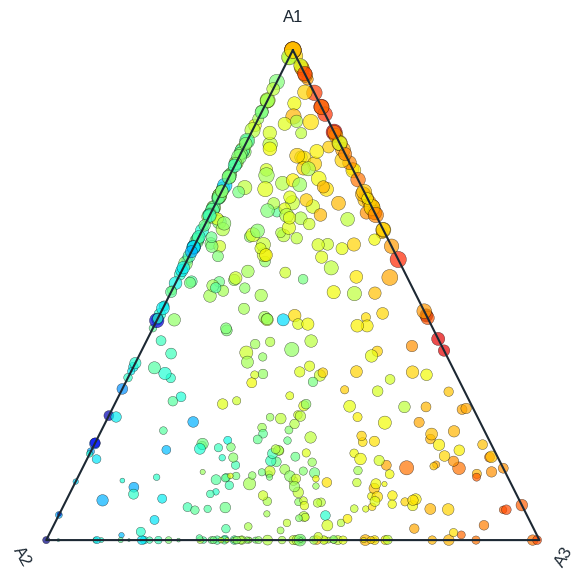

In [100]:
# STEP 1: Create Simplex plot. You can control the color of gridlines and borders (edges) of the simplex plots. 
# You can also control the fontcolor as well as figure size
create_simplex_ax(AA, grid_on = True, 
                  gridcolor = '#EAECEE', 
                  bordercolor='#1C2833', 
                  fontcolor = '#1C2833',
                  fig_size=[7,7])

# STEP 2: Map the alfa values to simplex plot
mapped_alfa = map_alfa_to_simplex(AA.alfa, AA)

# STEP 3: Use scatter plots to add the mapped alfa to simplex frame.
# The data points are colored by 'Biil' attribute, while sizes are correlated to normalised 'ChestDiam'
df['ChestDiamNorm'] = (df['ChestDiam'] - df['ChestDiam'].min()) / (df['ChestDiam'].max() - df['ChestDiam'].min())
plt.scatter(mapped_alfa[:,0], mapped_alfa[:,1], 
            c = df['Biil'], 
            cmap = 'jet', 
            s = df['ChestDiamNorm'] * 150, 
            alpha = 0.7, 
           edgecolor = 'black')
plt.show()

# Mapping other points to the simplex plot

You can use the functionalities in the package to map any other point to the simplex plot. For example, you can map the prototypes of your clusters to the plot and observe its relative location with other prototypes as well as the dataset. Here, for the purpose of illustration we calculate an average Male and Female and will show it on the plot.

In [101]:
X_ave_male = X_scaled[df['Gender']=='male'].mean(axis=0).reshape(1,-1)
X_ave_female = X_scaled[df['Gender']=='female'].mean(axis=0).reshape(1,-1)

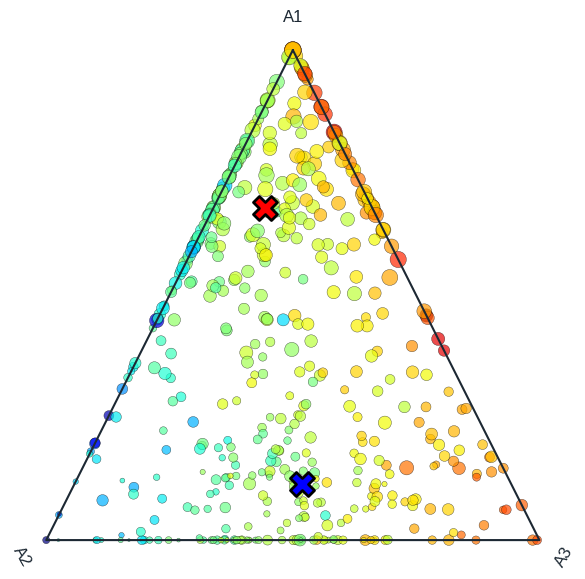

In [102]:
# STEP 1: Get the alfa values for male and female
_ , alfa_male = AA.transform(X_ave_male)
_ , alfa_female = AA.transform(X_ave_female)

# STEP 2: Create Simplex Plot
create_simplex_ax(AA, grid_on = True, 
                  gridcolor = '#EAECEE', 
                  bordercolor='#1C2833', 
                  fontcolor = '#1C2833',
                  fig_size=[7,7])

# STEP 3: Map alfas
mapped_alfa = map_alfa_to_simplex(AA.alfa, AA)
mapped_alfa_male = map_alfa_to_simplex(alfa_male, AA)
mapped_alfa_female = map_alfa_to_simplex(alfa_female, AA)

# STEP 4: Scatter data points
# All data points
df['ChestDiamNorm'] = (df['ChestDiam'] - df['ChestDiam'].min()) / (df['ChestDiam'].max() - df['ChestDiam'].min())
plt.scatter(mapped_alfa[:,0], mapped_alfa[:,1], 
            c = df['Biil'], 
            cmap = 'jet', 
            s = df['ChestDiamNorm'] * 150, 
            alpha = 0.7, 
           edgecolor = 'black')

# Average Male
plt.scatter(mapped_alfa_male[:,0], mapped_alfa_male[:,1], 
            marker = 'X', 
            s = 300, 
            color = 'red', 
            edgecolor = 'black',
            linewidth = 2)

# Average Female
plt.scatter(mapped_alfa_female[:,0], mapped_alfa_female[:,1], 
            marker = 'X', 
            s = 300, 
            color = 'blue', 
            edgecolor = 'black',
            linewidth = 2)

plt.show()

## Plotting profile

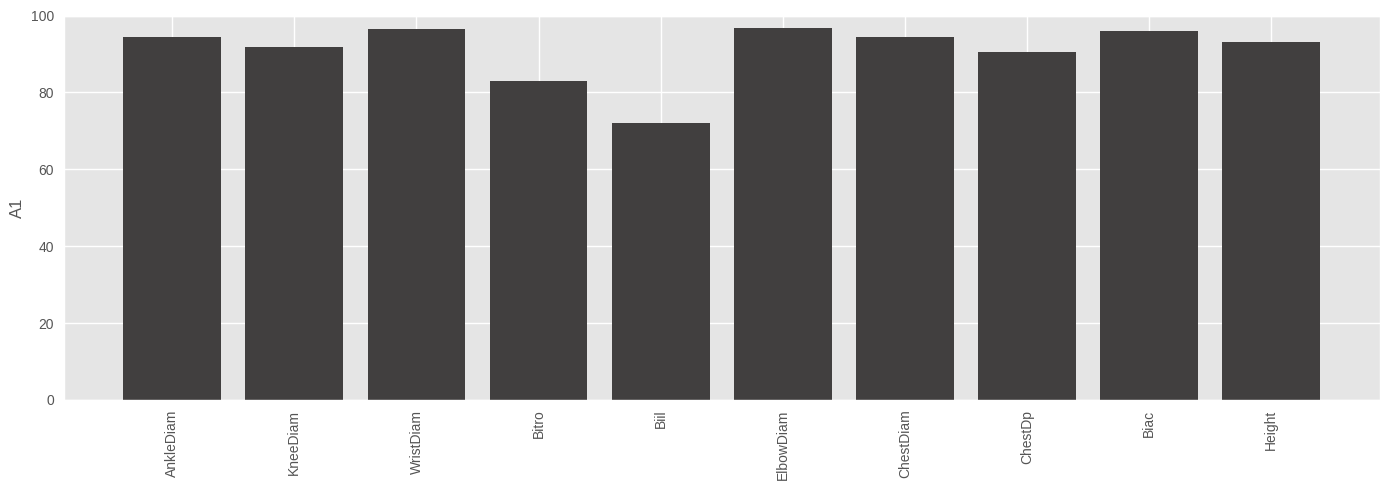

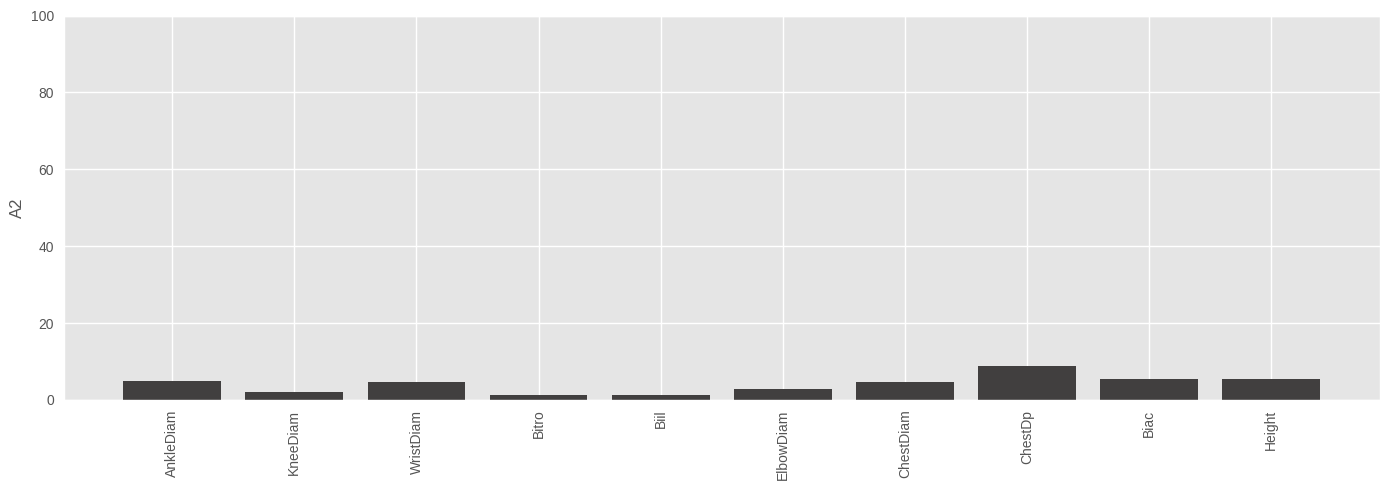

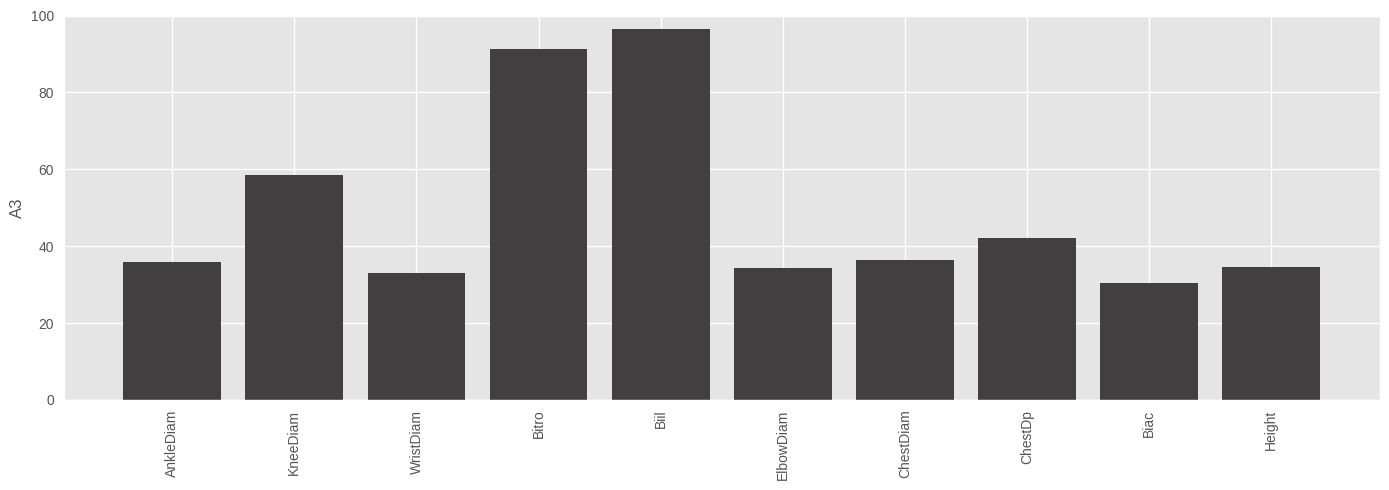

In [112]:
AA.plot_profile(lst_feat)

## Radar plot of profile of archetypes in the feature space

You can also plot the profile of the archetypes in a radar plot. As seen, A1 is extremely high in most features, A2 is extremely low, while A3 is moderate.

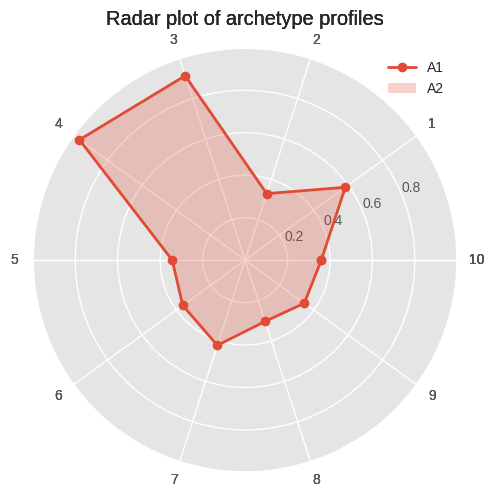

In [119]:
AA.plot_radar_profile(feature_cols=range(11), Title='Radar plot of archetype profiles')

#### Including feature names

You can pass feature names as an argument to get more informed plot.

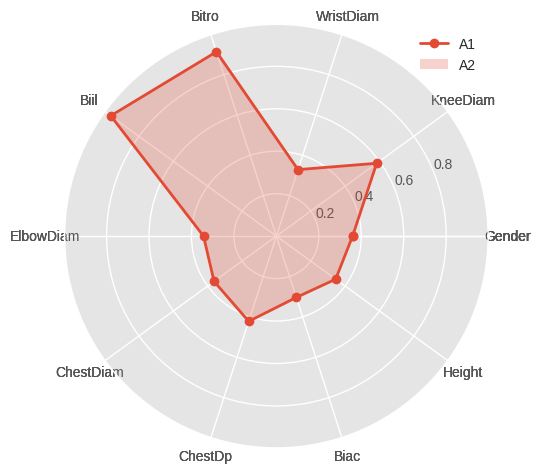

In [118]:
AA.plot_radar_profile(feature_cols=columns, Title='')

## Finding the most archetypal data points in the set

In [120]:
AA._extract_closes_match()

Attribute **.close_match** contains the most archetypal data points. This attribute is a dictionary where the keys are the archetypes. The first item in the tuple gives the index of the data point. The second item is the corresponding $\alpha$ array of that data point. Alfa can used to map the data point to a simplex plot or display it on a radar plot. It also shows how archetypal the data point is. For instance, in this example we see that **archetype 3** has perfect matching data point in the set. 

In [121]:
AA.close_match

{1: (6, array([0.96126367, 0.        , 0.03873633])),
 2: (300, array([0.05130891, 0.94869109, 0.        ])),
 3: (440, array([0.        , 0.00477782, 0.99522218]))}

## Radar plot of archetypal data points in archetype space

It shows the most archetypal data points. As seen, each is inclined toward one archetype.

ValueError: The number of FixedLocator locations (4), usually from a call to set_ticks, does not match the number of labels (3).

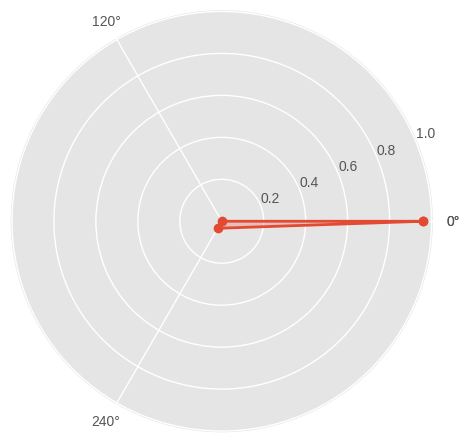

In [124]:
AA.plot_close_match(Title='')

## Radar plot of any data point in archetype space

ValueError: The number of FixedLocator locations (4), usually from a call to set_ticks, does not match the number of labels (3).

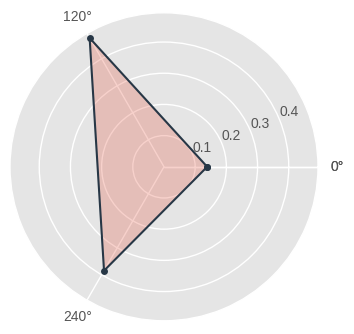

In [125]:
idx = 400
plot_radar_datapoint(AA, X_scaled[idx,:].reshape(1,-1), Title=f'Radar plot of datapoint index = {idx}')

## Parallel axis plot of the data points and archetypes

/home/users/u6853992/Documents/PhD/Workstation/PaperDrafts/BNPclass/archetypes.py:580: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_color.loc[-1] = 'arch'


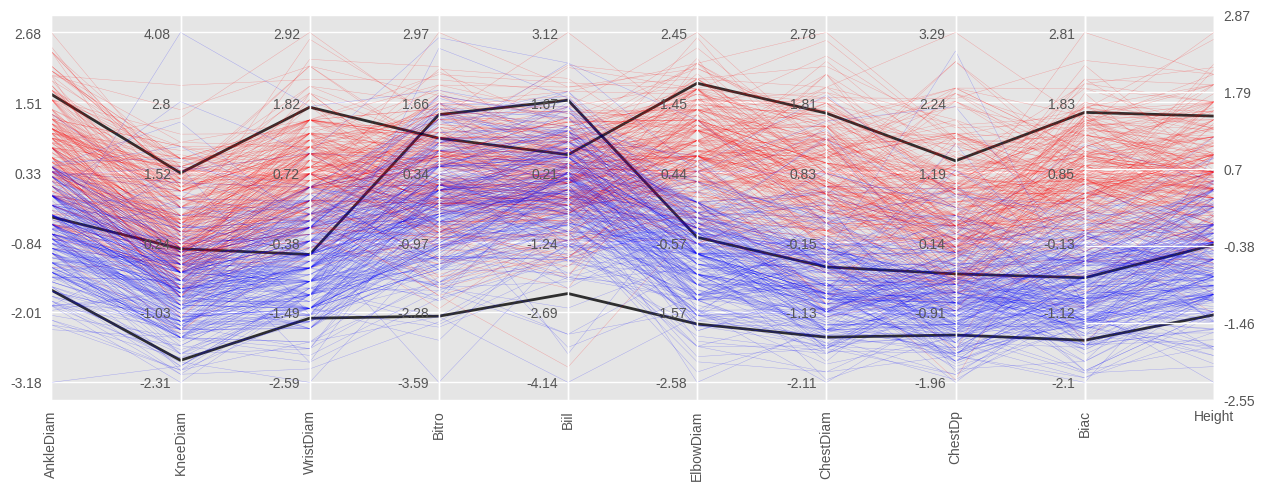

In [29]:
AA.parallel_plot(lst_feat, df_args[['color']], linewidth = '0.3', arch_color = 'black')

# Find an optimal seed number

Note that if you select to **randomly** initialized the archetypes, then the extracted archetypes depend on the initial guess.  Different groups pf archetypes can, together, explain the same variance, but it is possible we might want to find the seed number that maximizes the explained variance. You can use different searching algorithms such as Genetic Algorithm to find the best seed. Here, we simply scan a 1000 seed numbers.<br><br>

**NOTE:** If you select **'furthest_sum'** technique to initialize the archetypes, then, seed number does not have an effect.

In [30]:
seed_numbers = range(1000)
expl_var_old = 0.0
optmal_seed = None

for seed in seed_numbers:    
    AA = ArchetypalAnalysis(n_archetypes = 3, 
                        random_state = seed, 
                        initialize = 'random')
    try:        
        AA.fit(X_scaled)

        if (expl_var_old < AA.explained_variance_):
            expl_var_old = AA.explained_variance_
            optmal_seed = seed
            print(f'Found a new SEED: {seed}: {AA.explained_variance_:12.8f}')
    except:
        print(f'Optimisation failed for SEED: {seed}')

Found a new SEED: 0:   0.73242448
Found a new SEED: 2:   0.73245788
Found a new SEED: 4:   0.73426525
Found a new SEED: 99:   0.73428079


# Additional Exercise:

As an additional excercise you can redo the whole notbook with optimal seed number that was found and see how it impacts the results.